# SELF LEARNING LAB PROGRAM 1 – CONTINUOUS EVALUATION
## Gradient Descent, Fashion-MNIST MLP Optimizers, Regularization and Residual MLP

**Run this notebook in Google Colab.** It demonstrates:
1. Batch, stochastic and mini-batch gradient descent on a small synthetic dataset.
2. Momentum-based and adaptive optimizers with constant and scheduled learning rates.
3. Overfitting investigation.
4. Dropout, L2 regularization and data augmentation.
5. Early stopping.
6. Plain MLP vs Residual MLP under controlled settings.

**Dataset:** Fashion-MNIST (28×28 grayscale images, 10 classes). A reproducible subset is used to keep execution practical. Run cells from top to bottom. Actual scores and plots will appear after execution; they are not fabricated in advance.


## 1. Install and import required libraries

In [ ]:
!pip -q install torch torchvision numpy pandas matplotlib scikit-learn

In [ ]:
from pathlib import Path
import copy, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR = Path("/content/data")
OUT_DIR = Path("/content/lab1_outputs")
OUT_DIR.mkdir(exist_ok=True)

# Smaller defaults make the notebook practical on the free Colab runtime.
TRAIN_LIMIT = 6000
TEST_LIMIT = 1500
BATCH_SIZE = 128
EPOCHS = 4

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print("Device:", DEVICE)
print("Output folder:", OUT_DIR)

Device: cpu
Output folder: /content/lab1_outputs


## 2. Batch, stochastic and mini-batch gradient descent
We fit a simple linear model \(y = wx + b\) to a small synthetic dataset and compare the three update strategies.

,Method,Final weight,Final bias,Final MSE
0,Batch,2.8465,1.3360,0.1332
1,Stochastic,3.0350,1.5146,0.0746
2,Mini-batch (8),2.9920,1.5048,0.0726


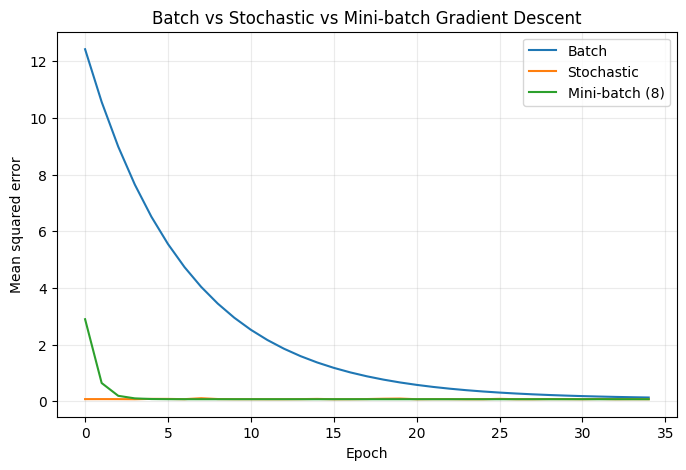

In [ ]:
def gradient_descent_demo():
    rng = np.random.default_rng(SEED)
    x = np.linspace(-2, 2, 80).reshape(-1, 1)
    y = 3.0*x + 1.5 + rng.normal(0, 0.35, size=x.shape)

    methods = {"Batch": len(x), "Stochastic": 1, "Mini-batch (8)": 8}
    rows, curves = [], {}

    for name, batch_size in methods.items():
        w, b, lr = 0.0, 0.0, 0.03
        losses = []
        for epoch in range(35):
            order = rng.permutation(len(x))
            for start in range(0, len(x), batch_size):
                ids = order[start:start+batch_size]
                error = (w*x[ids] + b) - y[ids]
                dw = float(2*np.mean(error*x[ids]))
                db = float(2*np.mean(error))
                w -= lr*dw
                b -= lr*db
            losses.append(float(np.mean((w*x+b-y)**2)))
        curves[name] = losses
        rows.append({"Method": name, "Final weight": w, "Final bias": b,
                     "Final MSE": losses[-1]})

    result = pd.DataFrame(rows)
    display(result.round(4))
    result.to_csv(OUT_DIR/"gradient_descent_comparison.csv", index=False)

    plt.figure(figsize=(8,5))
    for name, values in curves.items():
        plt.plot(values, label=name)
    plt.xlabel("Epoch")
    plt.ylabel("Mean squared error")
    plt.title("Batch vs Stochastic vs Mini-batch Gradient Descent")
    plt.legend()
    plt.grid(alpha=.25)
    plt.show()

gradient_descent_demo()

## 3. Load and prepare Fashion-MNIST
The training subset is split into training and validation portions. The test subset is kept separate for final evaluation.

In [ ]:
basic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])
augmented_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=3),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

def make_loaders(augment=False):
    train_transform = augmented_transform if augment else basic_transform
    train_full = datasets.FashionMNIST(
        root=DATA_DIR, train=True, download=True, transform=train_transform
    )
    test_full = datasets.FashionMNIST(
        root=DATA_DIR, train=False, download=True, transform=basic_transform
    )

    gen = torch.Generator().manual_seed(SEED)
    train_indices = torch.randperm(len(train_full), generator=gen)[:TRAIN_LIMIT].tolist()
    test_indices = torch.randperm(len(test_full), generator=gen)[:TEST_LIMIT].tolist()

    train_subset = Subset(train_full, train_indices)
    test_subset = Subset(test_full, test_indices)

    val_size = int(0.15 * len(train_subset))
    train_size = len(train_subset) - val_size
    train_part, val_part = random_split(
        train_subset, [train_size, val_size], generator=gen
    )

    train_loader = DataLoader(train_part, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_part, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 301kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.2MB/s]


Training images: 5100
Validation images: 900
Test images: 1500


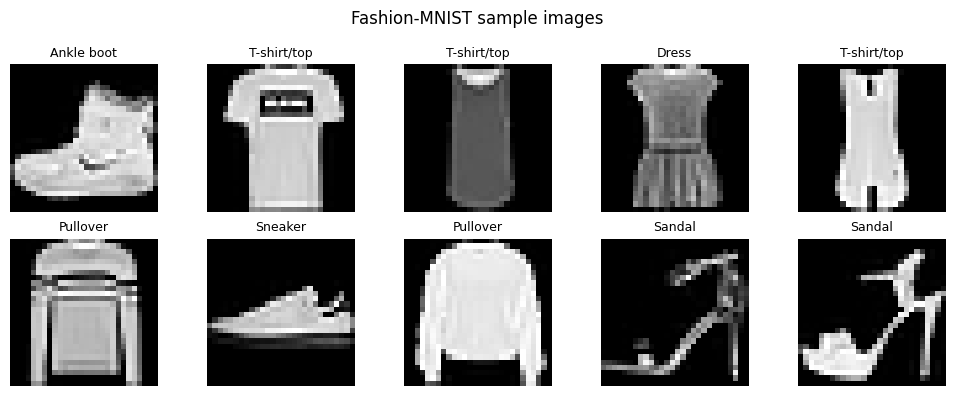

In [ ]:
# Display a few sample images
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
raw = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
fig, axes = plt.subplots(2, 5, figsize=(10,4))
for i, ax in enumerate(axes.flat):
    image, label = raw[i]
    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Fashion-MNIST sample images")
plt.tight_layout()
plt.show()

## 4. Define plain and residual MLP models
A residual block adds its input to the block's transformed output (skip connection).

In [ ]:
class PlainMLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

class ResidualMLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.flatten = nn.Flatten()
        self.input_layer = nn.Linear(784, 256)
        self.block1 = nn.Sequential(
            nn.Linear(256,256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256,256)
        )
        self.block2 = nn.Sequential(
            nn.Linear(256,256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256,256)
        )
        self.head = nn.Sequential(nn.ReLU(), nn.Linear(256,10))

    def forward(self, x):
        x = self.input_layer(self.flatten(x))
        x = torch.relu(x + self.block1(x))
        x = torch.relu(x + self.block2(x))
        return self.head(x)

print("Plain and residual MLP classes defined.")

Plain and residual MLP classes defined.


## 5. Training and evaluation utilities
The best model checkpoint is selected using validation loss. Test accuracy is calculated only after training.

In [ ]:
def evaluate_loss_accuracy(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return total_loss/total, correct/total

def train_experiment(name, model_kind="plain", optimizer_name="adam",
                     schedule=False, dropout=0.0, weight_decay=0.0,
                     augment=False, early_stop=False, epochs=EPOCHS):
    train_dl, val_dl, test_dl = make_loaders(augment=augment)
    model = (ResidualMLP(dropout) if model_kind == "residual"
             else PlainMLP(dropout)).to(DEVICE)

    if optimizer_name == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=0.03)
    elif optimizer_name == "momentum":
        optimizer = torch.optim.SGD(model.parameters(), lr=0.03, momentum=0.9)
    elif optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    elif optimizer_name == "rmsprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001, momentum=0.9)
    else:
        raise ValueError("Unknown optimizer")

    scheduler = (torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)
                 if schedule else None)
    criterion = nn.CrossEntropyLoss()
    history = []
    best_val_loss = float("inf")
    best_state = None
    patience, wait = 2, 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_dl:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(labels)

        train_loss = running_loss / len(train_dl.dataset)
        val_loss, val_acc = evaluate_loss_accuracy(model, val_dl, criterion)
        history.append({
            "experiment": name, "epoch": epoch+1,
            "train_loss": train_loss, "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": optimizer.param_groups[0]["lr"]
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if scheduler:
            scheduler.step()
        if early_stop and wait >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    _, test_acc = evaluate_loss_accuracy(model, test_dl, criterion)
    result = {
        "experiment": name, "model": model_kind, "optimizer": optimizer_name,
        "schedule": schedule, "dropout": dropout, "weight_decay": weight_decay,
        "augmentation": augment, "early_stopping": early_stop,
        "epochs_run": len(history), "best_val_loss": best_val_loss,
        "test_accuracy": test_acc
    }
    pd.DataFrame(history).to_csv(OUT_DIR/f"{name}_history.csv", index=False)
    return result, history

print("Training utilities ready.")

Training utilities ready.


## 6. Optimizer and learning-rate comparison
This compares SGD, momentum SGD, Adam, scheduled Adam and scheduled RMSprop. Each experiment starts with a fresh model and the same data split.

In [ ]:
optimizer_configs = [
    ("sgd_constant", "sgd", False),
    ("momentum_constant", "momentum", False),
    ("adam_constant", "adam", False),
    ("adam_scheduled", "adam", True),
    ("rmsprop_scheduled", "rmsprop", True),
]

optimizer_results, optimizer_histories = [], {}
for name, opt_name, use_schedule in optimizer_configs:
    print("Running:", name)
    result, hist = train_experiment(
        name=name, optimizer_name=opt_name, schedule=use_schedule
    )
    optimizer_results.append(result)
    optimizer_histories[name] = hist
    print(f"  test accuracy: {result['test_accuracy']:.4f}")

optimizer_table = pd.DataFrame(optimizer_results)
display(optimizer_table[["experiment","epochs_run","best_val_loss","test_accuracy"]].round(4))
optimizer_table.to_csv(OUT_DIR/"optimizer_comparison.csv", index=False)

Running: sgd_constant
  test accuracy: 0.7520
Running: momentum_constant
  test accuracy: 0.8107
Running: adam_constant
  test accuracy: 0.8347
Running: adam_scheduled
  test accuracy: 0.8373
Running: rmsprop_scheduled
  test accuracy: 0.7860


,experiment,epochs_run,best_val_loss,test_accuracy
0,sgd_constant,4,0.7175,0.7520
1,momentum_constant,4,0.4941,0.8107
2,adam_constant,4,0.4725,0.8347
3,adam_scheduled,4,0.4658,0.8373
4,rmsprop_scheduled,4,0.7169,0.7860


## 7. Investigate overfitting and regularization
We compare an unregularized baseline with dropout, L2 weight decay, data augmentation and early stopping. Look at training-versus-validation loss, not only test accuracy.

In [ ]:
regularization_configs = [
    ("overfit_baseline", dict()),
    ("dropout", dict(dropout=0.35)),
    ("l2_regularization", dict(weight_decay=1e-4)),
    ("data_augmentation", dict(augment=True)),
    ("early_stopping", dict(early_stop=True)),
]

regularization_results, regularization_histories = [], {}
for name, kwargs in regularization_configs:
    print("Running:", name)
    result, hist = train_experiment(name=name, **kwargs)
    regularization_results.append(result)
    regularization_histories[name] = hist
    print(f"  epochs: {result['epochs_run']} | test accuracy: {result['test_accuracy']:.4f}")

reg_table = pd.DataFrame(regularization_results)
display(reg_table[["experiment","epochs_run","best_val_loss","test_accuracy"]].round(4))
reg_table.to_csv(OUT_DIR/"regularization_comparison.csv", index=False)

Running: overfit_baseline
  epochs: 4 | test accuracy: 0.8207
Running: dropout
  epochs: 4 | test accuracy: 0.8313
Running: l2_regularization
  epochs: 4 | test accuracy: 0.8273
Running: data_augmentation
  epochs: 4 | test accuracy: 0.7387
Running: early_stopping
  epochs: 4 | test accuracy: 0.8393


,experiment,epochs_run,best_val_loss,test_accuracy
0,overfit_baseline,4,0.5129,0.8207
1,dropout,4,0.4865,0.8313
2,l2_regularization,4,0.4572,0.8273
3,data_augmentation,4,0.7663,0.7387
4,early_stopping,4,0.4506,0.8393


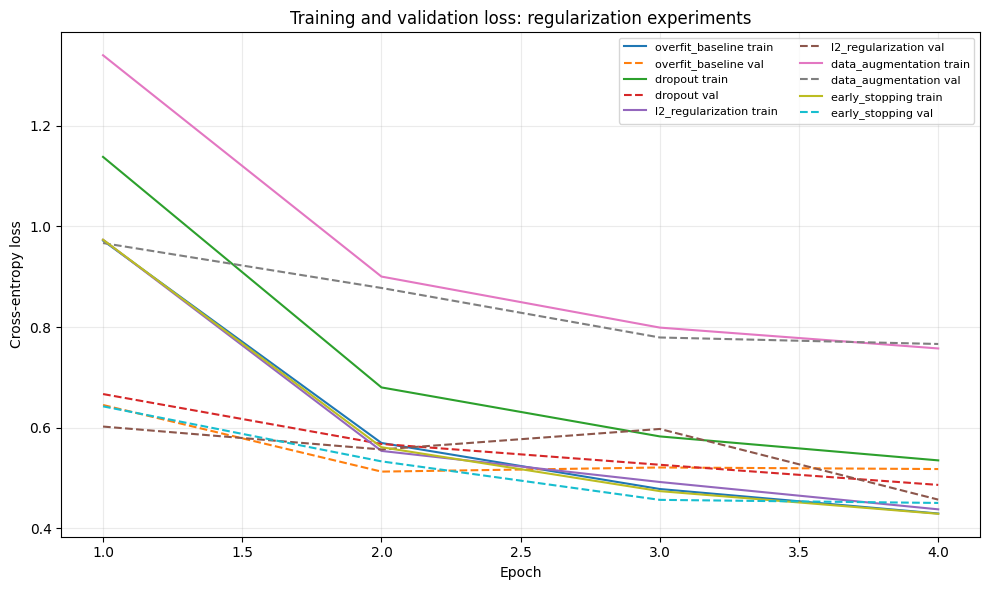

In [ ]:
plt.figure(figsize=(10,6))
for name, hist in regularization_histories.items():
    epochs = [r["epoch"] for r in hist]
    plt.plot(epochs, [r["train_loss"] for r in hist], label=f"{name} train")
    plt.plot(epochs, [r["val_loss"] for r in hist], linestyle="--", label=f"{name} val")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss: regularization experiments")
plt.legend(fontsize=8, ncol=2)
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 8. Plain MLP vs Residual MLP
Both models use the same subset, split, optimizer, regularization settings and epoch budget. The only intended difference is the architecture.

In [ ]:
architecture_results = []
architecture_histories = {}

for name, kind in [("plain_mlp", "plain"), ("residual_mlp", "residual")]:
    print("Running:", name)
    result, hist = train_experiment(
        name=name, model_kind=kind, optimizer_name="adam",
        dropout=0.2, weight_decay=1e-4, epochs=EPOCHS
    )
    architecture_results.append(result)
    architecture_histories[name] = hist
    print(f"  test accuracy: {result['test_accuracy']:.4f}")

architecture_table = pd.DataFrame(architecture_results)
display(architecture_table[["experiment","epochs_run","best_val_loss","test_accuracy"]].round(4))
architecture_table.to_csv(OUT_DIR/"plain_vs_residual.csv", index=False)

Running: plain_mlp
  test accuracy: 0.8240
Running: residual_mlp
  test accuracy: 0.8327


,experiment,epochs_run,best_val_loss,test_accuracy
0,plain_mlp,4,0.4802,0.8240
1,residual_mlp,4,0.4424,0.8327


## 9. Combined result summary and observations
Use the generated tables to write your final observations. The best model should be selected from the measured results, not assumed in advance.

In [ ]:
all_results = pd.DataFrame(
    optimizer_results + regularization_results + architecture_results
)
display(all_results[[
    "experiment","model","optimizer","schedule","dropout","weight_decay",
    "augmentation","early_stopping","epochs_run","test_accuracy"
]].round(4).sort_values("test_accuracy", ascending=False))
all_results.to_csv(OUT_DIR/"complete_experiment_summary.csv", index=False)

best_row = all_results.loc[all_results["test_accuracy"].idxmax()]
print("\nHighest test accuracy in this run:")
print(best_row[["experiment","test_accuracy"]].to_string())

,experiment,model,optimizer,schedule,dropout,weight_decay,augmentation,early_stopping,epochs_run,test_accuracy
9,early_stopping,plain,adam,False,0.00,0.0000,False,True,4,0.8393
3,adam_scheduled,plain,adam,True,0.00,0.0000,False,False,4,0.8373
2,adam_constant,plain,adam,False,0.00,0.0000,False,False,4,0.8347
11,residual_mlp,residual,adam,False,0.20,0.0001,False,False,4,0.8327
6,dropout,plain,adam,False,0.35,0.0000,False,False,4,0.8313
7,l2_regularization,plain,adam,False,0.00,0.0001,False,False,4,0.8273
10,plain_mlp,plain,adam,False,0.20,0.0001,False,False,4,0.8240
5,overfit_baseline,plain,adam,False,0.00,0.0000,False,False,4,0.8207
1,momentum_constant,plain,momentum,False,0.00,0.0000,False,False,4,0.8107
4,rmsprop_scheduled,plain,rmsprop,True,0.00,0.0000,False,False,4,0.7860



Highest test accuracy in this run:
experiment       early_stopping
test_accuracy          0.839333


## 10. Save and download all generated outputs
The ZIP includes CSV result tables and plot files. Download it after all experiments have completed.

In [ ]:
import shutil, os
zip_base = "/content/SL_Lab_Program_1_Results"
shutil.make_archive(zip_base, "zip", OUT_DIR)
print("Created:", zip_base + ".zip")

from google.colab import files
files.download(zip_base + ".zip")

Created: /content/SL_Lab_Program_1_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>